In [3]:
# IMPORTS
import numpy as np
import xarray as xr
from datetime import date, timedelta
import pandas as pd

from metpy.units import units
from metpy.calc import potential_temperature
import metpy.constants as constants

import matplotlib.pyplot as plt

from matplotlib.ticker import ScalarFormatter
import metpy.calc as mpcalc
import geocat.viz as gv

In [4]:
plotsdir = '/glade/u/home/athornton/plots/vert_profiles/'

In [5]:
i = 2

# Northern Track based on 850 hPa V Variance
Lons_N = [-34.,-11., 14.]
Lats_N = [12., 21.5, 21.5]

# Southern Track based on 600 hPa V Variance
Lons_S = [-34., -11., 14.]
Lats_S = [12., 12., 8]

# label for legend
label = ['Ocean', 'Coast', 'Land']

delta = 5
colorN = ['midnightblue', 'steelblue', 'lightsteelblue']
colorS = ['maroon', 'brown', 'lightcoral']

latN = Lats_N[i] + delta
latS = Lats_N[i] - delta
lonW = Lons_N[i] - delta
lonE = Lons_N[i] + delta

data_base = '/glade/work/athornton/mse/era5_processed_data/'
data_file = data_base + 'jas_means/mse_jas_1998_2022.nc'
dsmse = xr.open_dataset(data_file)

In [6]:
ds = dsmse.sel(latitude=slice(latN,latS), longitude=slice(lonW,lonE)).mean(dim={'latitude','longitude'}, keep_attrs=True)

Text(0.5, 0, 'MSE (kJ/kg)')

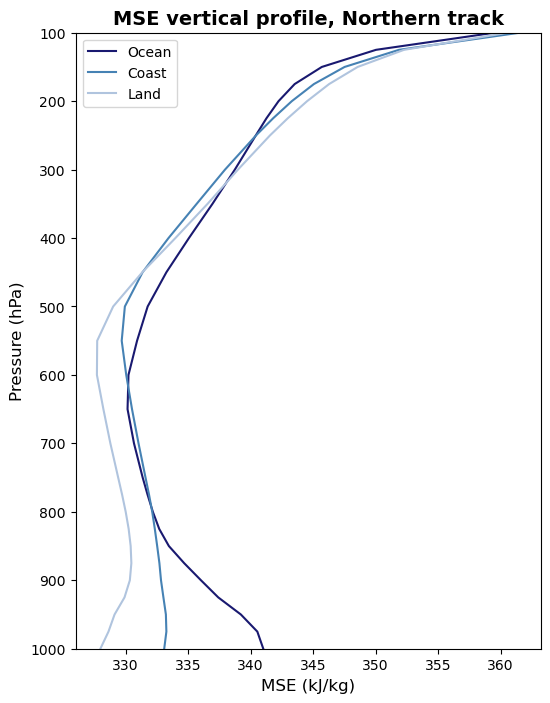

In [7]:
# Generate figure (set its size (width, height) in inches) and axes
fig, ax = plt.subplots(figsize=(6, 8))  # Share y-axis for consistency

plt.rcParams['savefig.dpi'] = 255 # Set image quality
gv.set_axes_limits_and_ticks(
    ax=ax,
    ylim=(1000, 100),  # Explicitly set the correct limits
    yticks=ds["level"])

# Force the y-axis to remain reversed
#ax[i, j].set_ylim(1000, 100)  

# Find at most 11 ticks on the y-axis at 'nice' locations
max_yticks = 11
yloc = plt.MaxNLocator(max_yticks)
ax.yaxis.set_major_locator(yloc)

# Change formatter or else tick values will be in exponential form
ax.yaxis.set_major_formatter(ScalarFormatter())
for i in range (0,3):
    latN = Lats_N[i] + delta
    latS = Lats_N[i] - delta
    lonW = Lons_N[i] - delta
    lonE = Lons_N[i] + delta
    ds = dsmse.sel(latitude=slice(latN,latS), longitude=slice(lonW,lonE)).mean(dim={'latitude','longitude'}, keep_attrs=True)
    ax.plot(ds.MSE, ds.MSE.level, label=(label[i]), color=colorN[i])
    ax.legend()
plt.title('MSE vertical profile, Northern track', weight='bold', fontsize=14)
ax.set_ylabel('Pressure (hPa)', fontsize=12)
ax.set_xlabel('MSE (kJ/kg)', fontsize=12)
#plt.savefig(plotsdir+'vert_profile_n.png')

Text(0.5, 0, 'MSE (kJ/kg)')

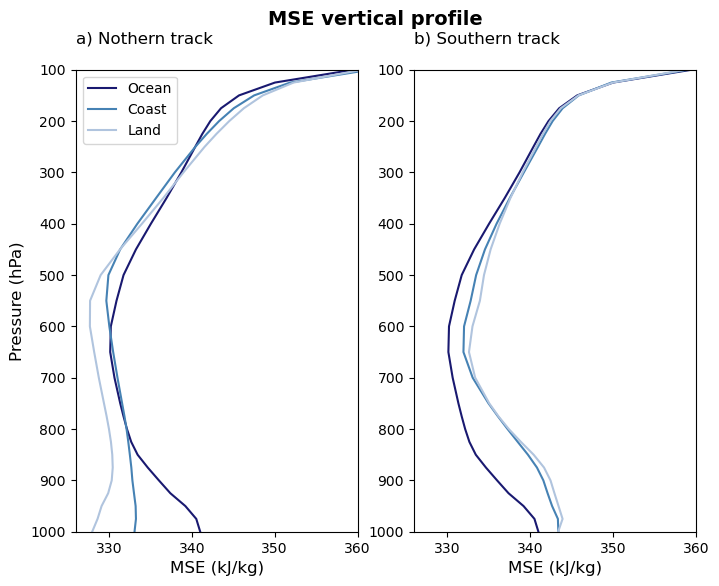

In [8]:
# Generate figure (set its size (width, height) in inches) and axes
fig, ax = plt.subplots(1,2,figsize=(8, 6))  # Share y-axis for consistency

plt.rcParams['savefig.dpi'] = 255 # Set image quality
gv.set_axes_limits_and_ticks(
    ax=ax[0],
    ylim=(1000, 100),  # Explicitly set the correct limits
    yticks=ds["level"])
gv.set_axes_limits_and_ticks(
    ax=ax[1],
    ylim=(1000, 100),  # Explicitly set the correct limits
    yticks=ds["level"])

# Force the y-axis to remain reversed
#ax[i, j].set_ylim(1000, 100)  

# Find at most 11 ticks on the y-axis at 'nice' locations
max_yticks = 11
yloc = plt.MaxNLocator(max_yticks)
ax[0].yaxis.set_major_locator(yloc)
ax[1].yaxis.set_major_locator(yloc)

# Change formatter or else tick values will be in exponential form
ax[0].yaxis.set_major_formatter(ScalarFormatter())
ax[1].yaxis.set_major_formatter(ScalarFormatter())
for i in range (0,3):
    latN = Lats_N[i] + delta
    latS = Lats_N[i] - delta
    lonW = Lons_N[i] - delta
    lonE = Lons_N[i] + delta
    ds = dsmse.sel(latitude=slice(latN,latS), longitude=slice(lonW,lonE)).mean(dim={'latitude','longitude'}, keep_attrs=True)
    ax[0].plot(ds.MSE, ds.MSE.level, label=(label[i]), color=colorN[i])
    latN = Lats_S[i] + delta
    latS = Lats_S[i] - delta
    lonW = Lons_S[i] - delta
    lonE = Lons_S[i] + delta
    ds = dsmse.sel(latitude=slice(latN,latS), longitude=slice(lonW,lonE)).mean(dim={'latitude','longitude'}, keep_attrs=True)
    ax[1].plot(ds.MSE, ds.MSE.level, label=(label[i]), color=colorN[i])
    ax[0].legend()
    ax[0].set_xlim(326, 360)
    ax[1].set_xlim(326, 360)
    gv.set_titles_and_labels(ax[0],
                 lefttitle='a) Nothern track',
                 lefttitlefontsize=12,
                 labelfontsize=10)
    gv.set_titles_and_labels(ax[1],
                 lefttitle='b) Southern track',
                 lefttitlefontsize=12,
                 labelfontsize=10)


plt.suptitle('MSE vertical profile', weight='bold', fontsize=14)
ax[0].set_ylabel('Pressure (hPa)', fontsize=12)
ax[1].set_xlabel('MSE (kJ/kg)', fontsize=12)
ax[0].set_xlabel('MSE (kJ/kg)', fontsize=12)
#plt.savefig(plotsdir+'vert_profile.png')